In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]


In [5]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_on_30-60N_markov.nc')[['P_DW']]

ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_off_30-60N_markov.nc')[['P_DW']]
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle3_30-60N_markov.nc')[['P_DW']]
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle4_1990-2020_30-60N_markov.nc')[['P_DW']]
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle3_30-60N_markov.nc')[['P_DW']]
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle4_30-60N_markov.nc')[['P_DW']]
# CESM2 is replaced by the CMIP6 models, loaded in the CMIP6 cells below
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/imerg_30-60N_markov.nc')[['P_DW']]

icon_cycle4 = icon_cycle4.isel(year=slice(0,5))



In [6]:
land_sea_ifs_high = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/ifs_hpx2048_lsm_30-60N.nc')['lsm']
land_sea_ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
land_sea_icon_zoom10 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
land_sea_imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)

ifs_on_land = ifs_on.where(land_sea_ifs_high > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_ifs_high > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_ifs_cycle3 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_ifs_zoom9 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_icon_zoom10 < 1, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_icon_zoom9 < 1, np.nan)
imerg_land = imerg.where(land_sea_imerg < 100, np.nan)


In [7]:
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "value"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "value"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "cell"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "cell"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))


In [8]:
ifs_on_land = ifs_on_land * 100
ifs_off_land = ifs_off_land * 100
ifs_cycle3_land = ifs_cycle3_land * 100 
ifs_cycle4_land = ifs_cycle4_land * 100
icon_cycle3_land = icon_cycle3_land * 100
icon_cycle4_land = icon_cycle4_land * 100
imerg_land = imerg_land * 100

In [9]:
ifs_on_land_DW = ifs_on_land.P_DW.where(~ifs_on_land.P_DW.isnull(), drop=True)
ifs_off_land_DW = ifs_off_land.P_DW.where(~ifs_off_land.P_DW.isnull(), drop=True)
ifs_cycle3_land_DW = ifs_cycle3_land.P_DW.where(~ifs_cycle3_land.P_DW.isnull(), drop=True)
ifs_cycle4_land_DW = ifs_cycle4_land.P_DW.where(~ifs_cycle4_land.P_DW.isnull(), drop=True)
icon_cycle3_land_DW = icon_cycle3_land.P_DW.where(~icon_cycle3_land.P_DW.isnull(), drop=True)
icon_cycle4_land_DW = icon_cycle4_land.P_DW.where(~icon_cycle4_land.P_DW.isnull(), drop=True)
imerg_land_DW = imerg_land.P_DW.where(~imerg_land.P_DW.isnull(), drop=True)


In [10]:
#For IMERG weighting
# 1D cos(lat) weights
lat_rad = np.deg2rad(imerg.lat)
coslat = np.cos(lat_rad)                   # dims: ['lat']

w_lat = xr.DataArray(
    coslat,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon)
w_imerg_2d = w_lat.broadcast_like(land_sea_imerg)
# Mask to land only (same land mask you use for imerg_land)
w_imerg_2d = w_imerg_2d.where(land_sea_imerg < 100)
#w_imerg_2d = w_imerg_2d / w_imerg_2d.sum()
# Broadcast spatial weights to (year, lat, lon):
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_imerg_2d.values, imerg.P_DW.shape),
    dims=imerg.P_DW.dims,
    coords=imerg.P_DW.coords,
)

w_imerg_land = w_imerg_full.where(land_sea_imerg < 100, np.nan)
# Stack in exactly the same way as imerg_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))
# Drop weights where the data is NaN to keep alignment
w_imerg_land_DW = w_imerg_land.where(~imerg_land_DW.isnull(), drop=True)

#print(w_imerg_land)

#w_imerg = w_imerg_land.values.ravel()


In [11]:
print(imerg_land.P_DW.isnull().sum().item())

5033470


## CMIP6 multi-model distribution (replaces CESM2)

One file per member from `cmip6_markov_calc.py`: the probability that a dry day is followed by a wet day (`P_DW`, wet = pr > 1 mm/day), for each May–Oct season and grid point, 30–60°N, shown in %.
- **One member per model:** the first member of each model (`CMIP6_MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f), the same member as in the other CMIP6 notebooks.
- **Per model:** all years and land cells are pooled. Land is `sftlf > 0`, and each value gets a cos(lat) area weight, as for CESM2 before.
- **Equal model weights:** each model's weights are scaled to sum to 1, so the CMIP6 curve is the average of the per-model curves.
- **Grey band:** the range (`CMIP6_BAND_RANGE`) of the per-model KDE curves, with the same `bw_adjust` as the lines.
- **Models without an sftlf file** (BCC-CSM2-MR): the mask of `FALLBACK_MASK_MODEL` is used, matched to the nearest grid point.

In [12]:
import re
from collections import defaultdict

CMIP6_DIR           = '/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/CMIP6'   # output of cmip6_markov_calc.py
SFTLF_DIR           = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
CMIP6_EXPERIMENT    = 'historical'
CMIP6_YEARS         = None      # e.g. (1985, 2014) to use only those years; None = all years in the files
CMIP6_EXCLUDE       = []        # model names to leave out, e.g. ['BCC-CSM2-MR']
CMIP6_MEMBERS_PER_MODEL = 1     # first N members of each model (sorted r, i, p, f); None = all members
FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask for models without an sftlf file (BCC-CSM2-MR)
CMIP6_BAND_RANGE    = (10, 90)  # inter-model band, percentiles across models: (0, 100) = min-max, (10, 90) = 10-90%
CMIP6_BAND_COLOR    = '#888888' # grey, so it does not hide the pale IFS_2.8_deep_on line
CMIP6_BAND_ALPHA    = 0.15


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = np.asarray(values)[sorter]
    cumw = np.cumsum(np.asarray(weights)[sorter])
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


# ── per model: land values of the first member(s), cos(lat) weights scaled to sum to 1 ──
pat = re.compile(rf'^markov_(?P<model>[^_]+)_{CMIP6_EXPERIMENT}_(?P<member>r\d+i\d+p\d+f\d+)_30-60N\.nc$')
member_files = defaultdict(list)
for f in os.listdir(CMIP6_DIR):
    if (m := pat.match(f)) and m['model'] not in CMIP6_EXCLUDE:
        member_files[m['model']].append((m['member'], f))
fallback_sftlf = xr.open_dataset(find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()

cmip6_models = {}   # model -> dict(values, weights): land values of all years and their normalised weights
for model in sorted(member_files, key=str.lower):
    chosen = sorted(member_files[model], key=lambda mf: member_sort_key(mf[0]))[:CMIP6_MEMBERS_PER_MODEL]
    vals, wts = [], []
    for mem, f in chosen:
        da = xr.open_dataset(os.path.join(CMIP6_DIR, f))['P_DW'].load() * 100   # (year, lat, lon), in %
        if CMIP6_YEARS is not None:
            da = da.sel(year=slice(*CMIP6_YEARS))
        mask_path = find_sftlf(model)
        sftlf = nearest_regrid(xr.open_dataset(mask_path)['sftlf'].load() if mask_path else fallback_sftlf,
                               da.lat.values, da.lon.values)
        land = (sftlf > 0).values
        w2d = np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon'])
        v = da.values[:, land]                                          # (year, n_land)
        w = np.broadcast_to(w2d[land], v.shape)
        ok = np.isfinite(v)
        vals.append(v[ok])
        wts.append(w[ok])
    v, w = np.concatenate(vals), np.concatenate(wts)
    cmip6_models[model] = dict(values=v, weights=w / w.sum(), members=[mem for mem, _ in chosen])
    print(f"{model:14s} {', '.join(m for m, _ in chosen)}, {da.sizes['year']} years, {land.sum():5d} land cells, "
          f"median {weighted_quantile(v, w, 0.5):.1f}%  mask: {os.path.basename(mask_path) if mask_path else FALLBACK_MASK_MODEL + ' (fallback)'}")

# ── multi-model sample: every model's weights sum to 1 / n_models ──
n_models = len(cmip6_models)
cmip6_land_DW   = xr.DataArray(np.concatenate([d['values'] for d in cmip6_models.values()]), dims='sample')
w_cmip6_land_DW = xr.DataArray(np.concatenate([d['weights'] / n_models for d in cmip6_models.values()]), dims='sample')
print(f'\n{n_models} models, {cmip6_land_DW.size} values in total')


ACCESS-ESM1-5  r1i1p1f1, 165 years,  2720 land cells, median 23.1%  mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 165 years,  4341 land cells, median 22.3%  mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, 165 years,  4758 land cells, median 16.3%  mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, 165 years,   858 land cells, median 21.9%  mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
CESM2          r1i1p1f1, 165 years,  5119 land cells, median 22.7%  mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 165 years,  3442 land cells, median 16.9%  mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, 165 years, 11444 land cells, median 21.7%  mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 165 years,  1579 land cells, median 20.9%  mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, 165 years,  5256

In [13]:
print(np.median(imerg_land_DW))


21.705426356589147


In [14]:
print(weighted_quantile(cmip6_land_DW.values, w_cmip6_land_DW.values, 0.5))   # CMIP6 median (area-weighted, equal model weights)

21.37404441833496


In [15]:
print(np.median(ifs_off_land_DW))

19.696969696969695


In [16]:
print(np.median(ifs_on_land_DW))

18.4


In [17]:
print(np.median(icon_cycle4_land_DW))

20.43010752688172


In [18]:
print(np.median(icon_cycle3_land_DW))

16.551724137931036


In [19]:
print(np.median(ifs_cycle3_land_DW))

18.51851851851852


In [20]:
print(np.median(ifs_cycle4_land_DW))

18.51851851851852


In [21]:
print(ifs_cycle3_land_DW.mean())

<xarray.DataArray 'P_DW' ()> Size: 8B
array(18.64003921)
Coordinates:
    time     datetime64[ns] 8B 2020-01-15


In [22]:
print(ifs_cycle4_land_DW.mean())

<xarray.DataArray 'P_DW' ()> Size: 8B
array(18.31562209)


## DW

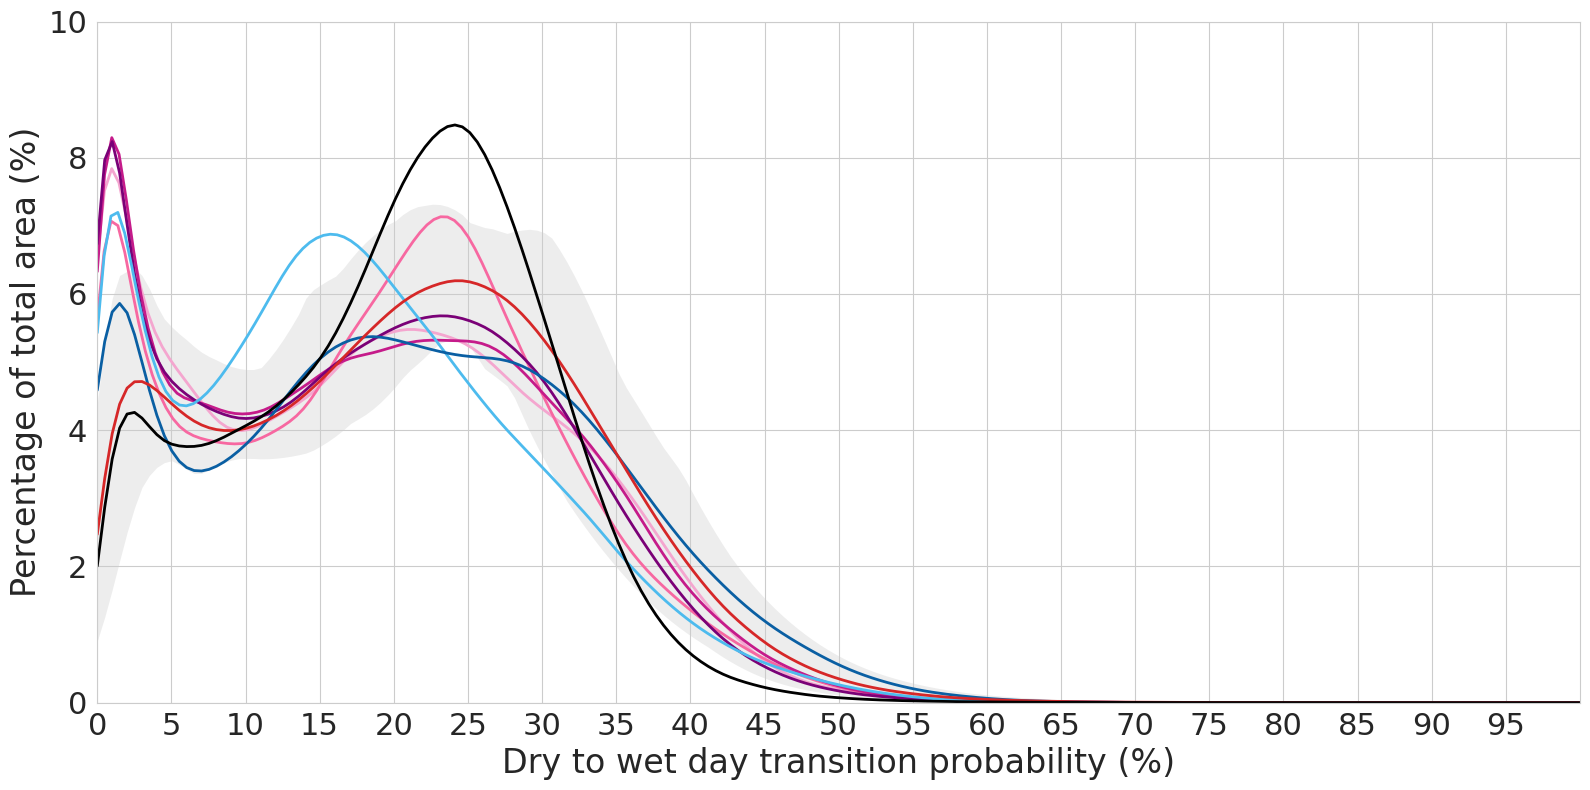

In [23]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 100
bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)


datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land_DW,       ones_like_da(ifs_on_land_DW),       '#F4A6CF', 'IFS_2.8_deep_on'),
    (ifs_off_land_DW,      ones_like_da(ifs_off_land_DW),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land_DW,   ones_like_da(ifs_cycle3_land_DW),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land_DW,   ones_like_da(ifs_cycle4_land_DW),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land_DW,  ones_like_da(icon_cycle3_land_DW),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land_DW,  ones_like_da(icon_cycle4_land_DW),  '#0A5FA3', 'ICON_9'),

    # CMIP6 multi-model & IMERG: area weights from above
    (cmip6_land_DW,        w_cmip6_land_DW,                    '#D62728', 'CMIP6'),
    (imerg_land_DW,        w_imerg_land_DW,                    '#000000',       'IMERG'),
]


plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 4b) CMIP6 inter-model band: range of the per-model KDE curves (same bandwidth rule and bw_adjust as
#     the lines), evaluated on the same x values as the CMIP6 line
from scipy.stats import gaussian_kde
cmip6_line = ax.get_lines()[[lab for *_, lab in datasets].index('CMIP6')]
x_grid = cmip6_line.get_xdata()
model_curves = []
for d in cmip6_models.values():
    k = gaussian_kde(d['values'], weights=d['weights'])
    k.set_bandwidth(k.factor * 2.0)                    # bw_adjust=2.0, as in sns.kdeplot above
    model_curves.append(k(x_grid) * 100 * bin_width)
band_lo, band_hi = np.percentile(np.array(model_curves), CMIP6_BAND_RANGE, axis=0)
ax.fill_between(x_grid, band_lo, band_hi, color=CMIP6_BAND_COLOR, alpha=CMIP6_BAND_ALPHA, linewidth=0, zorder=0)

# 5) Labels, limits, legend
xl = 'Dry to wet day transition probability (%)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 5)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]
legend_handles.append(Patch(facecolor=CMIP6_BAND_COLOR, alpha=CMIP6_BAND_ALPHA, edgecolor='none'))
legend_labels.append('CMIP6 model range' if tuple(CMIP6_BAND_RANGE) == (0, 100)
                     else f'CMIP6 models {CMIP6_BAND_RANGE[0]}-{CMIP6_BAND_RANGE[1]}%')

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_markov_DW_histo_CMIP6mmm_band.pdf', format='pdf',bbox_inches='tight')

plt.show()